# Sesión 8 · Modelos de nowcasting: red neuronal de corto y largo plazo (LSTM)

Actividad práctica · 20 minutos en vivo

Esta actividad es distinta a las dos anteriores en dos sentidos. Primero, `nowcast_lstm` no
comparte la interfaz de scikit-learn: los datos entran con la fecha como columna y no como
índice, y el modelo necesita ver los datos completos para poder predecir. Segundo, el
entrenamiento tarda, así que en vivo se estima una versión deliberadamente pequeña.

Al cierre se comparan los ocho modelos del taller sobre la misma muestra de prueba.

## Preparación

La celda siguiente carga los datos, la procesa (deflactación, desestacionalización,
tasas de crecimiento), la restringe a los predictores del ejercicio y arma la
partición de entrenamiento y prueba. Es idéntica en las tres actividades, así que
los resultados de las sesiones 6, 7 y 8 son directamente comparables entre sí.

Ejecutar tal cual, no hay nada que modificar.

In [1]:
import os
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# =========================================================
# Parametros editables
# =========================================================
data_file = "data_BOL.csv"
meta_file = "meta_BOL.csv"

train_start_date = pd.to_datetime("2017-03-01")
test_start_date = pd.to_datetime("2023-09-01")

target_variable = "RGDP0000"
meta_col = "ticket"
cpi = "MCPI0000"

# Seis predictores con lectura economica clara para el PIB de Barbados.
# Para adaptar el taller a Bolivia basta con cambiar esta lista y el archivo
# de datos.
PREDICTORES = [
    "RCEM0007",   # Produccion de cemento total
    "GGTR0024",   # Google Trends: "impuestos nacionales"
    "XIMP0004",   # Importaciones de bienes de consumo duradero
    "RPES0001",   # Superficie en permisos de construccion
    "RPER0001",   # Numero de permisos de construccion
    "GGTR0010",   # Google Trends: "delivery"
    "GGTR0030",   # Google Trends: "laptop"
    "MBCB0002",   # Billetes y monedas en poder del publico
    "XFRD0014",   # Tipo de cambio BRL/USD
    "RRSU0009",   # Residuos solidos recolectados, Trinidad
    "XUSA0001",   # Exportaciones de EE.UU. a Bolivia
    "GGTR0039",   # Google Trends: "toyota"
    "RRSU0007",   # Residuos solidos recolectados, Tarija
    "XEXP0184",   # Exportaciones a Japon
    "XIMP0044",   # Importaciones de Ecuador
]

ETIQUETAS = {
    "RCEM0007": "Produccion de cemento",
    "GGTR0024": "Google Trends: impuestos nacionales",
    "XIMP0004": "Import. consumo duradero",
    "RPES0001": "Superficie permisos construccion",
    "RPER0001": "Permisos de construccion",
    "GGTR0010": "Google Trends: delivery",
    "GGTR0030": "Google Trends: laptop",
    "MBCB0002": "Billetes y monedas en poder del publico",
    "XFRD0014": "Tipo de cambio BRL/USD",
    "RRSU0009": "Residuos solidos Trinidad",
    "XUSA0001": "Export. de EE.UU. a Bolivia",
    "GGTR0039": "Google Trends: toyota",
    "RRSU0007": "Residuos solidos Tarija",
    "XEXP0184": "Export. a Japon",
    "XIMP0044": "Import. de Ecuador",
}

# Carpetas relativas, iguales a las del pipeline del taller
d = os.getcwd() + "/"
PATH_DATA = os.path.join(d, "..", "data")
PATH_OUTPUT = os.path.join(d, "..", "output")
os.makedirs(PATH_OUTPUT, exist_ok=True)

# Archivo donde se acumulan los RMSE de las tres sesiones
RESULTADOS_FILE = os.path.join(PATH_OUTPUT, "resultados_taller.csv")

# =========================================================
# Carga y procesamiento
# =========================================================
data = pd.read_csv(
    os.path.join(PATH_DATA, data_file), parse_dates=["date"], index_col="date"
)
metadata = pd.read_csv(os.path.join(PATH_DATA, meta_file))
test_end_date = data[target_variable].dropna().index.max()

# Deflactacion por IPC (base: promedio de 2017)
base = data[cpi][data.index.year == 2017].mean()
nominal = metadata.loc[metadata["nominal"] == 1][meta_col].values
for column in data.columns:
    if column in nominal:
        data[column] = data[column] / data[cpi] * base
data.drop(columns=[cpi], inplace=True)
data = data.drop(columns=[c for c in data.columns if "RGDP" in c and c != target_variable])

# Desestacionalizacion
quarterly = metadata.loc[metadata["freq"].str.lower().str.contains("q")][meta_col].values
already_sa = metadata.loc[metadata["sa"] == 1][meta_col].values
data = data.loc[:, data.notna().sum() >= 24]
for column in data.columns:
    if column in already_sa:
        continue
    serie = data[column].dropna()
    periodo = 4 if column in quarterly else 12
    decomp = seasonal_decompose(serie, model="additive", extrapolate_trend="freq", period=periodo)
    data[column] = data[column] - decomp.seasonal

# Tasas de crecimiento
for column in data.columns:
    if column in quarterly:
        no_nan = data[column].dropna()
        var = no_nan.pct_change(periods=1, fill_method=None) * 100
        res = pd.Series(np.nan, index=data.index)
        res.loc[var.index] = var
        data[column] = res
    else:
        era_nan = data[column].isna()
        var = data[column].pct_change(periods=1, fill_method=None) * 100
        prev_nan = data[column].shift(1).isna()
        var[prev_nan | era_nan] = np.nan
        data[column] = var
data.replace([np.inf, -np.inf], np.nan, inplace=True)

for column in [c for c in data.columns if c not in quarterly]:
    sub = data[data.index <= test_start_date][column]
    if sub.isna().sum() / len(sub) > 0.75:
        data.drop(column, axis=1, inplace=True)

data = data[~(data.index < train_start_date)]
data = data.dropna(how="all", axis=0)

metadata["months_lag"] = pd.to_numeric(metadata["months_lag"], errors="coerce").fillna(1).astype(int)
tickets_ok = metadata[metadata.months_lag <= 5][meta_col].tolist()
data = data[[c for c in data.columns if c in tickets_ok or "RGDP" in c]]

# =========================================================
# Restriccion a los quince predictores y agregacion trimestral
# =========================================================
columnas = [target_variable] + [c for c in PREDICTORES if c in data.columns]
faltantes = [c for c in PREDICTORES if c not in data.columns]
if faltantes:
    print(f"Aviso: no estan en la base y se omiten -> {faltantes}")
data = data[columnas]

agg_map = metadata.set_index(meta_col)["agg_method"].to_dict()
agg_funcs = {
    col: (agg_map[col] if agg_map.get(col) in ["mean", "last", "sum"] else "mean")
    for col in data.columns
}
data = data.resample("QE").agg(agg_funcs)
data = data[data.index > "2016-01-01"]
data = data[data.index < "2026-01-01"]
data = data.dropna(how="any", axis=0)

train = data[data.index < test_start_date]
test = data[data.index >= test_start_date]

X_train = train.drop(target_variable, axis=1)
y_train = train[target_variable]
X_test = test.drop(target_variable, axis=1)
y_obs = test[target_variable]

predictores = list(X_train.columns)
etiquetas = [ETIQUETAS.get(c, c) for c in predictores]

In [2]:
def rmse(observado, predicho):
    '''Raiz del error cuadratico medio.'''
    return float(np.sqrt(np.mean((np.asarray(observado) - np.asarray(predicho)) ** 2)))


def tabla_comparativa(predicho, nombre="Predicho"):
    '''Tabla de observado contra predicho con el error en puntos porcentuales.'''
    t = pd.DataFrame({"Observado": y_obs, nombre: np.asarray(predicho)}, index=y_obs.index)
    t["Error (pp)"] = t[nombre] - t["Observado"]
    return t


def guardar_resultado(modelo, valor_rmse, sesion, notas=""):
    '''Anade o actualiza una fila en la tabla de resultados del taller.'''
    fila = pd.DataFrame([{
        "modelo": modelo,
        "rmse": round(float(valor_rmse), 4),
        "sesion": sesion,
        "notas": notas,
        "actualizado": datetime.now().strftime("%Y-%m-%d %H:%M"),
    }])
    if os.path.exists(RESULTADOS_FILE):
        prev = pd.read_csv(RESULTADOS_FILE)
        prev = prev[prev["modelo"] != modelo]
        fila = pd.concat([prev, fila], ignore_index=True)
    fila.to_csv(RESULTADOS_FILE, index=False)
    return fila.sort_values("rmse").reset_index(drop=True)


def tabla_resultados():
    '''Devuelve todo lo acumulado hasta ahora, ordenado de mejor a peor.'''
    if not os.path.exists(RESULTADOS_FILE):
        print("Todavia no hay resultados guardados de sesiones anteriores.")
        return pd.DataFrame(columns=["modelo", "rmse", "sesion", "notas"])
    return pd.read_csv(RESULTADOS_FILE).sort_values("rmse").reset_index(drop=True)


def grafico_observado_predicho(predicho, nombre, color="#C0392B", ax=None):
    '''Serie observada contra la predicha en la muestra de prueba.'''
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 4))
    ax.plot(y_obs.index, y_obs.values, "o-", color="#2C3E50", lw=2, label="Observado")
    ax.plot(y_obs.index, np.asarray(predicho), "s--", color=color, lw=2, label=nombre)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_ylabel("Crecimiento del PIB (%)")
    ax.set_title(f"Observado contra predicho · {nombre}")
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)
    plt.tight_layout()
    return ax


def resumen_datos():
    '''Imprime el estado de la base para verificar que todo cargo bien.'''
    print("=" * 62)
    print("BASE LISTA PARA LA ACTIVIDAD")
    print("=" * 62)
    print(f"Variable objetivo : {target_variable}")
    print(f"Predictores       : {len(predictores)} -> {', '.join(predictores)}")
    print(f"Entrenamiento     : {train.index.min():%Y-%m} a {train.index.max():%Y-%m} "
          f"({len(train)} trimestres)")
    print(f"Prueba            : {test.index.min():%Y-%m} a {test.index.max():%Y-%m} "
          f"({len(test)} trimestres)")
    print("=" * 62)
    return data.tail(5)

In [3]:
import torch
from nowcast_lstm.LSTM import LSTM

resumen_datos()

BASE LISTA PARA LA ACTIVIDAD
Variable objetivo : RGDP0000
Predictores       : 15 -> RCEM0007, GGTR0024, XIMP0004, RPES0001, RPER0001, GGTR0010, GGTR0030, MBCB0002, XFRD0014, RRSU0009, XUSA0001, GGTR0039, RRSU0007, XEXP0184, XIMP0044
Entrenamiento     : 2018-03 a 2023-06 (22 trimestres)
Prueba            : 2023-09 a 2025-12 (10 trimestres)


,RGDP0000,RCEM0007,GGTR0024,XIMP0004,RPES0001,RPER0001,GGTR0010,GGTR0030,MBCB0002,XFRD0014,RRSU0009,XUSA0001,GGTR0039,RRSU0007,XEXP0184,XIMP0044
date,,,,,,,,,,,,,,,,
2024-12-31,-1.796869,24.255262,1.274906,2.151986,10.601334,-0.998774,6.405377,-0.476744,0.820420,3.289575,-9.940634,-32.388920,3.830076,-3.348885,26.636685,8.136632
2025-03-31,-1.573398,-15.612189,-3.826321,-1.960024,17.709496,-7.650847,0.804614,-0.407338,2.106395,-1.716580,-3.714773,55.889930,0.609912,7.112024,-0.905111,33.819886
2025-06-30,4.780676,10.935812,10.082885,-6.225064,47.243170,58.856175,12.496958,-0.099805,-1.524221,-1.047646,12.248516,6.883326,1.775363,7.830539,34.387584,12.539012
2025-09-30,-1.946797,-9.012130,-7.687357,20.054238,16.024566,-42.232160,-0.491450,-1.123689,1.156407,-1.490886,6.539701,16.015076,-2.588310,-1.714156,27.496636,2.841150
2025-12-31,-2.223851,-0.984984,-3.008830,-6.012833,0.597970,-13.210715,29.277048,6.496671,-2.121670,0.563737,8.057551,16.641544,4.757171,-2.206910,-3.248129,-20.048214


In [4]:
# Lo acumulado en las sesiones 6 y 7
tabla_resultados()

,modelo,rmse,sesion,notas,actualizado
0,Random Forest,2.8342,7,"n_estimators=200, max_features=5",2026-10-09 14:08
1,LASSO,2.8948,6,alpha=0.5,2026-10-08 09:39
2,Gradient Boosting,2.9668,7,"lr=0.15, n_estimators=200",2026-10-09 14:20
3,Ridge,3.1651,6,alpha=10.0,2026-10-08 09:39
4,Elastic Net,3.3013,6,"alpha=0.1, l1_ratio=0.25",2026-10-08 09:39
5,OLS,3.3728,6,Referencia sin penalizacion,2026-10-08 09:39
6,LSTM,3.7027,8,"n_timesteps=4, n_models=15, episodes=100, n_hi...",2026-10-12 09:37
7,Arbol de decision,4.1009,7,max_depth=2,2026-10-09 13:59


## El formato de los datos

Este paso es la fuente habitual de errores. A diferencia de los modelos anteriores, que
reciben una matriz de predictores y un vector objetivo por separado, el LSTM recibe la tabla
completa con la fecha como columna. Además hay que pasarle todo el dataset al momento de
predecir, no solo el tramo de prueba, porque para construir la ventana de cada trimestre
necesita los trimestres previos.

In [5]:
train_lstm = train.reset_index()
test_lstm = test.reset_index()
full_lstm = pd.concat([train_lstm, test_lstm]).reset_index(drop=True)

print("Columnas que recibe el modelo:", list(train_lstm.columns))
print(f"Entrenamiento: {train_lstm.shape}   Base completa: {full_lstm.shape}")
train_lstm.head(3)

Columnas que recibe el modelo: ['date', 'RGDP0000', 'RCEM0007', 'GGTR0024', 'XIMP0004', 'RPES0001', 'RPER0001', 'GGTR0010', 'GGTR0030', 'MBCB0002', 'XFRD0014', 'RRSU0009', 'XUSA0001', 'GGTR0039', 'RRSU0007', 'XEXP0184', 'XIMP0044']
Entrenamiento: (22, 17)   Base completa: (32, 17)


,date,RGDP0000,RCEM0007,GGTR0024,XIMP0004,RPES0001,RPER0001,GGTR0010,GGTR0030,MBCB0002,XFRD0014,RRSU0009,XUSA0001,GGTR0039,RRSU0007,XEXP0184,XIMP0044
0,2018-03-31,-0.942760,10.080049,14.765357,-5.533400,22.265034,18.640125,5.575395,2.984264,1.457485,0.217053,-6.580586,-2.104137,8.163158,-10.517812,95.909210,57.824032
1,2018-06-30,4.358146,4.526456,-3.581323,8.736249,14.711052,-10.283070,29.157102,-0.870390,1.352834,5.054198,-3.140138,-2.084351,-4.399400,20.333088,15.717170,-33.700175
2,2018-09-30,-2.817027,-4.506154,-0.942167,-7.283187,-10.979020,-10.147766,33.183110,2.816165,0.287423,2.352940,2.469138,45.553779,2.927797,-6.290285,13.715211,8.688595


### Gráfico 1 · Qué es una ventana temporal

Los modelos de las sesiones 6 y 7 tratan cada trimestre como una observación independiente:
para predecir el segundo trimestre de 2024 solo miran los indicadores de ese trimestre. El
LSTM en cambio recibe una ventana de trimestres consecutivos y aprende qué patrón dentro de
esa secuencia anticipa el PIB.

El parámetro `n_timesteps` es el largo de esa ventana. Con 4 significa un año de historia
por cada predicción. El gráfico sombrea las primeras ventanas y marca el trimestre que se
predice a partir de cada una. Es la versión trimestral de la lámina de las ventanas
deslizantes de la teoría, donde las barras eran de doce meses.

Trimestres de entrenamiento: 22
Ventanas disponibles con n_timesteps=4: 18
Ese segundo numero es la verdadera muestra efectiva del LSTM.


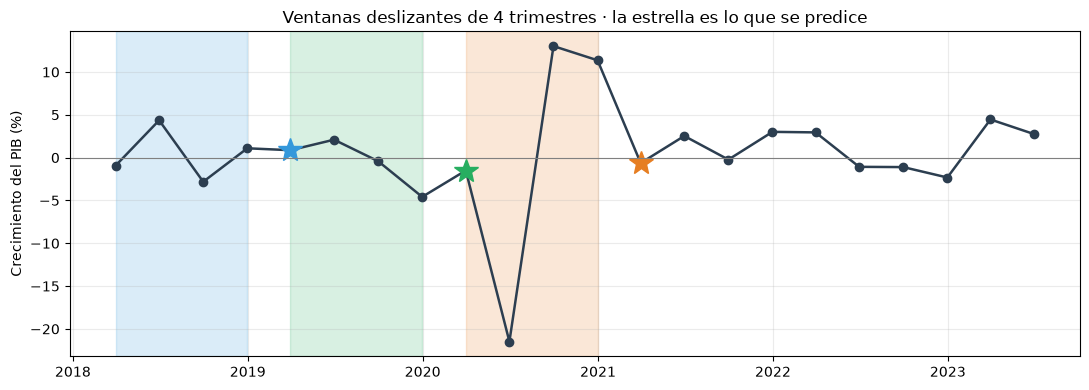

In [6]:
n_pasos = 4
serie = train[target_variable]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(serie.index, serie.values, "o-", color="#2C3E50", lw=1.8)

for k, (inicio, color) in enumerate([(0, "#3498DB"), (4, "#27AE60"), (8, "#E67E22")]):
    v_ini = serie.index[inicio]
    v_fin = serie.index[inicio + n_pasos - 1]
    objetivo = serie.index[inicio + n_pasos]
    ax.axvspan(v_ini, v_fin, color=color, alpha=0.18)
    ax.plot(objetivo, serie.loc[objetivo], "*", color=color, markersize=18)

ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("Crecimiento del PIB (%)")
ax.set_title(f"Ventanas deslizantes de {n_pasos} trimestres · la estrella es lo que se predice")
ax.grid(alpha=0.25)
plt.tight_layout()

print(f"Trimestres de entrenamiento: {len(train)}")
print(f"Ventanas disponibles con n_timesteps={n_pasos}: {len(train) - n_pasos}")
print("Ese segundo numero es la verdadera muestra efectiva del LSTM.")

## Estimación

| Parámetro | Efecto |
|---|---|
| `n_timesteps` | Largo de la ventana de historia. Más largo captura más dinámica pero consume observaciones. |
| `n_models` | Cuántas redes se entrenan y se promedian. Cada una parte de pesos aleatorios distintos. |
| `train_episodes` | Épocas de entrenamiento por red. |
| `n_hidden` | Unidades ocultas de la celda. Más capacidad y más riesgo de sobreajuste. |
| `n_layers` | Capas apiladas. Con series cortas conviene dejarlo en 1. |
| `lr` | Tamaño del paso del optimizador. |
| `dropout` | Fracción de unidades que se apagan al azar durante el entrenamiento. |

Incluso con `n_hidden=4` la red tiene unos 320 parámetros frente a las veintitantas ventanas
de entrenamiento que se vieron arriba, así que tiene capacidad de sobra para memorizar la
muestra. Por eso `n_hidden` y `n_layers` se dejan en el mínimo, se limitan las épocas y se
promedian varias redes. Después de estimar se imprime el RMSE en entrenamiento junto al de
prueba, y la distancia entre ambos muestra cuánto de esa memorización se logró contener.

La configuración de abajo está reducida a propósito para que corra en menos de un minuto.
La del pipeline de producción usa `n_models=50` y `train_episodes=100`. A diferencia de las
sesiones anteriores no hay una tabla de exploración automática: entrenar cada configuración
toma tiempo real, así que aquí conviene correr solo una vez con estos valores. `train(quiet=False)`
ya deja ver, época por época, cómo baja la pérdida dentro de cada una de las `n_models` redes,
que es el equivalente en esta sesión al resumen de coeficientes que tuvo el OLS.

Una aclaración sobre `n_timesteps`, porque el número no coincide con el de la teoría y la
diferencia no es un recorte. El pipeline real corre el LSTM sobre datos mensuales y usa
`n_timesteps=12`, o sea doce meses de historia por predicción. Esta actividad agrega todo a
frecuencia trimestral para que los ocho modelos del taller se puedan comparar en la misma
tabla, así que cuatro trimestres son exactamente esos mismos doce meses. El valor equivale,
no se está mirando menos historia.

Lo que sí se pierde al agregar a trimestral es justamente la ventaja propia del LSTM. En
producción el modelo consume las series en su frecuencia original, mensual o incluso diaria,
sin promediarlas antes, y ese manejo nativo de frecuencias mezcladas es algo que ninguno de
los otros siete modelos del taller sabe hacer. La tabla comparativa del cierre, entonces,
compara al LSTM con una mano atada.

In [7]:
n_timesteps = 4
n_models = 15
train_episodes = 100
n_hidden = 8

lstm_params = {
    "n_timesteps": n_timesteps,
    "fill_na_func": np.nanmean,
    "fill_ragged_edges_func": np.nanmean,
    "n_models": n_models,
    "train_episodes": train_episodes,
    "batch_size": 4,
    "decay": 0.99,
    "n_hidden": n_hidden,
    "n_layers": 1,
    "dropout": 0.0,
    "criterion": torch.nn.MSELoss(),
    "optimizer": torch.optim.Adam,
}

# Semilla fija para que el RMSE que va a la tabla no cambie en cada corrida
torch.manual_seed(1)
np.random.seed(1)

modelo_lstm = LSTM(data=train_lstm, target_variable=target_variable, **lstm_params)
modelo_lstm.train(quiet=False)

Training model 1
step :  0 loss :  10.770406723022461
step :  1 loss :  10.035968780517578
step :  2 loss :  9.241109848022461
step :  3 loss :  8.524150848388672
step :  4 loss :  7.470203399658203
step :  5 loss :  6.533453941345215
step :  6 loss :  5.681801795959473
step :  7 loss :  4.960383415222168
step :  8 loss :  4.472917556762695
step :  9 loss :  4.051541805267334
step :  10 loss :  3.7617650032043457
step :  11 loss :  3.5794103145599365
step :  12 loss :  3.444059133529663
step :  13 loss :  3.268287181854248
step :  14 loss :  3.1248691082000732
step :  15 loss :  3.0093040466308594
step :  16 loss :  2.876725673675537
step :  17 loss :  2.7921133041381836
step :  18 loss :  2.6286137104034424
step :  19 loss :  2.323960304260254
step :  20 loss :  2.1889991760253906
step :  21 loss :  2.111166477203369
step :  22 loss :  2.0281028747558594
step :  23 loss :  1.95656418800354
step :  24 loss :  1.9002010822296143
step :  25 loss :  1.8487920761108398
step :  26 loss :  1

In [8]:
preds_df = modelo_lstm.predict(full_lstm)
serie_pred = preds_df.set_index("date")["predictions"]
pred_lstm = serie_pred.loc[test_lstm["date"]].values

# RMSE en entrenamiento, para ver la brecha con el de prueba
pred_ent = serie_pred.reindex(y_train.index).dropna()
rmse_train_lstm = rmse(y_train.loc[pred_ent.index], pred_ent)

rmse_lstm = rmse(y_obs, pred_lstm)
print(f"RMSE en entrenamiento : {rmse_train_lstm:.4f}")
print(f"RMSE en prueba        : {rmse_lstm:.4f}")
print(f"Brecha                : {rmse_lstm - rmse_train_lstm:.4f}  <- si es grande, hay sobreajuste")

guardar_resultado("LSTM", rmse_lstm, sesion=8,
                  notas=f"n_timesteps={n_timesteps}, n_models={n_models}, "
                        f"episodes={train_episodes}, n_hidden={n_hidden}")

tabla_comparativa(pred_lstm, "LSTM")

RMSE en entrenamiento : 2.5506
RMSE en prueba        : 3.0062
Brecha                : 0.4556  <- si es grande, hay sobreajuste


,Observado,LSTM,Error (pp)
date,,,
2023-09-30,-1.823183,0.048442,1.871626
2023-12-31,-1.561182,0.600296,2.161478
2024-03-31,-1.627019,0.297900,1.924919
2024-06-30,6.097000,0.870929,-5.226071
2024-09-30,-4.062978,0.584543,4.647521
2024-12-31,-1.796869,-1.497601,0.299268
2025-03-31,-1.573398,1.058707,2.632105
2025-06-30,4.780676,1.355898,-3.424778
2025-09-30,-1.946797,0.885483,2.832280


### TU TURNO (opcional, si sobra tiempo): `n_timesteps`

Solo si hay margen, correr de nuevo el bloque de estimación con `n_timesteps = 8` (dos años
de historia en vez de uno) y comparar el RMSE contra el de arriba. El aviso de la celda de la
ventana temporal ya adelantó el costo: cada trimestre que se suma a la ventana es un trimestre
menos de muestra efectiva de entrenamiento. Si el RMSE empeora, esa es la razón más probable,
no que el modelo esté peor especificado.

No hace falta rehacer esto para cada valor posible, con una sola comparación contra el
`n_timesteps=4` de arriba alcanza para la discusión.

n_timesteps = 4
n_models = 15
train_episodes = 100
n_hidden = 8

lstm_params = {
    "n_timesteps": n_timesteps,
    "fill_na_func": np.nanmean,
    "fill_ragged_edges_func": np.nanmean,
    "n_models": n_models,
    "train_episodes": train_episodes,
    "batch_size": 4,
    "decay": 0.99,
    "n_hidden": n_hidden,
    "n_layers": 1,
    "dropout": 0.0,
    "criterion": torch.nn.MSELoss(),
    "optimizer": torch.optim.Adam,
}

# Semilla fija para que el RMSE que va a la tabla no cambie en cada corrida
torch.manual_seed(1)
np.random.seed(1)

modelo_lstm = LSTM(data=train_lstm, target_variable=target_variable, **lstm_params)
modelo_lstm.train(quiet=False)

### Gráfico 2 · Por qué dos entrenamientos no dan lo mismo

Los modelos de las sesiones anteriores son deterministas: con los mismos datos y los mismos
parámetros devuelven siempre el mismo número. El LSTM no, porque parte de pesos iniciales
aleatorios y el descenso de gradiente llega a un óptimo distinto en cada corrida.

La celda estima varias redes por separado y grafica sus predicciones individuales en gris
junto al promedio. La dispersión entre las líneas grises es la razón por la que el pipeline
promedia decenas de modelos en vez de quedarse con uno: la predicción individual es
demasiado inestable para reportarla a una autoridad monetaria. Es la misma idea del Random
Forest de la sesión 7, donde se promediaban árboles que se equivocaban distinto; la diferencia
es que allí la diversidad venía del bootstrap y del sorteo de variables, y aquí viene de los
pesos iniciales de cada red.


Desviacion tipica entre corridas, por trimestre: [2.433 2.196 1.988 1.023 1.039 1.829 0.774 1.931 0.854 1.73 ]


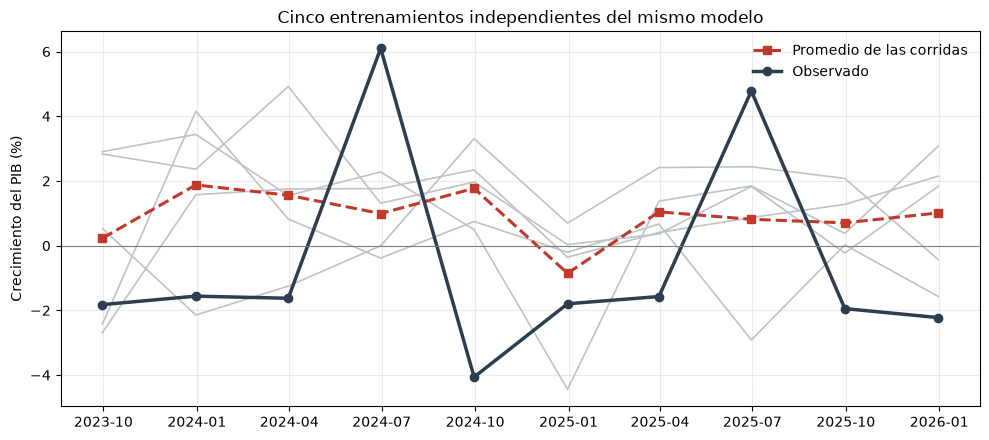

In [9]:
corridas = []
for semilla in range(5):
    torch.manual_seed(semilla)
    m = LSTM(data=train_lstm, target_variable=target_variable,
             **{**lstm_params, "n_models": 1, "train_episodes": 40})
    m.train(quiet=True)
    p = m.predict(full_lstm)
    corridas.append(
        p[p["date"].isin(test_lstm["date"])].set_index("date")["predictions"].values
    )

corridas = np.array(corridas)

fig, ax = plt.subplots(figsize=(10, 4.5))
for c in corridas:
    ax.plot(y_obs.index, c, color="#BDC3C7", lw=1.2)
ax.plot(y_obs.index, corridas.mean(axis=0), "s--", color="#C0392B", lw=2.2,
        label="Promedio de las corridas")
ax.plot(y_obs.index, y_obs.values, "o-", color="#2C3E50", lw=2.5, label="Observado")
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("Crecimiento del PIB (%)")
ax.set_title("Cinco entrenamientos independientes del mismo modelo")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
plt.tight_layout()

print(f"Desviacion tipica entre corridas, por trimestre: {corridas.std(axis=0).round(3)}")

## Cierre del taller: los ocho modelos

La tabla y el gráfico siguientes recogen todo lo estimado en las sesiones 6, 7 y 8 sobre la
misma muestra de prueba.

Tres lecturas para la discusión. Si algún modelo de aprendizaje automático no le gana al OLS,
eso no es un error del ejercicio sino el resultado esperable de una muestra de menos de
treinta trimestres. Si el LSTM queda mal ubicado, conviene recordar que aquí corrió en una
versión reducida, bastante más liviana que la del pipeline de producción, y además sobre
series agregadas a trimestral en vez de en su frecuencia original. Por último, además de
comparar los modelos entre sí, vale la pena contrastarlos con las estimaciones que ya se
producen internamente, para tener una idea más completa de su aporte.

In [10]:
resultados = tabla_resultados()
resultados

,modelo,rmse,sesion,notas,actualizado
0,Random Forest,2.8342,7,"n_estimators=200, max_features=5",2026-10-09 14:08
1,LASSO,2.8948,6,alpha=0.5,2026-10-08 09:39
2,Gradient Boosting,2.9668,7,"lr=0.15, n_estimators=200",2026-10-09 14:20
3,LSTM,3.0062,8,"n_timesteps=4, n_models=15, episodes=100, n_hi...",2026-10-12 09:38
4,Ridge,3.1651,6,alpha=10.0,2026-10-08 09:39
5,Elastic Net,3.3013,6,"alpha=0.1, l1_ratio=0.25",2026-10-08 09:39
6,OLS,3.3728,6,Referencia sin penalizacion,2026-10-08 09:39
7,Arbol de decision,4.1009,7,max_depth=2,2026-10-09 13:59


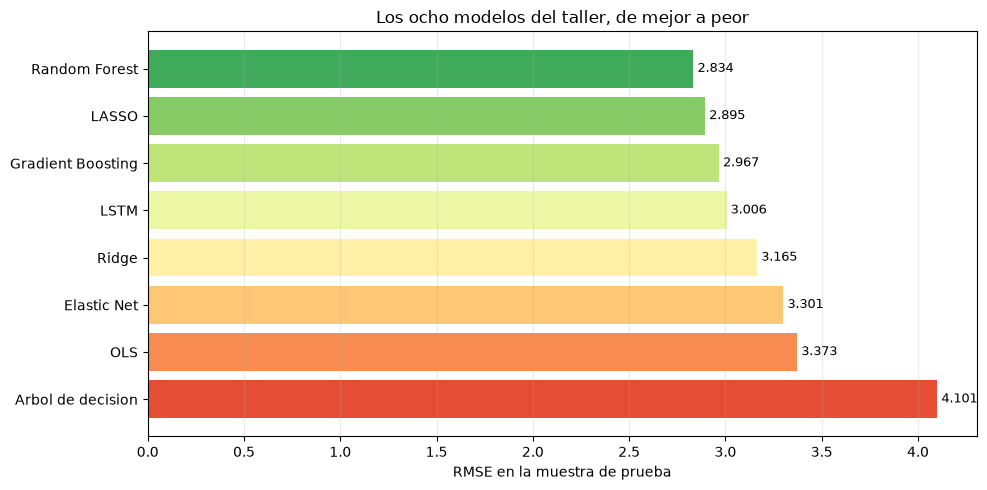

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
colores = plt.cm.RdYlGn_r(np.linspace(0.15, 0.85, len(resultados)))

ax.barh(resultados["modelo"], resultados["rmse"], color=colores)
ax.invert_yaxis()
ax.set_xlabel("RMSE en la muestra de prueba")
ax.set_title("Los ocho modelos del taller, de mejor a peor")
ax.grid(alpha=0.25, axis="x")

for i, v in enumerate(resultados["rmse"]):
    ax.text(v, i, f" {v:.3f}", va="center", fontsize=9)

plt.tight_layout()

## En preparación para el bloque presencial

El trabajo de estas tres sesiones se hizo con un grupo reducido de predictores elegidos de antemano y una
sola configuración por modelo. En el bloque presencial se corre el pipeline completo, con la
base entera y todas las especificaciones, así que conviene llegar practicando.

Una, practicar combinaciones de parámetros que den mejor RMSE en cada uno de los modelos de la
sesiones.

Dos, una respuesta escrita en dos o tres líneas a la pregunta de si el orden de la tabla
final se mantendría con otra partición de la muestra, por ejemplo moviendo el inicio de la
muestra de prueba un año atrás. Es fácil de verificar cambiando `test_start_date` en la celda de preparación de cada
notebook y volviendo a correr las actividades, y es la mejor forma de ver hasta qué
punto el ranking es una propiedad de los modelos o del trozo de historia que les tocó.